# Problem Set 1 — Study Key

**PPHA 30545 · Machine Learning for Public Policy · Fall 2026**

> **Note.** Claude wrote this key on Oct 16, after the submission deadline, as study material for the in-person quiz. It is not a submission. Compare it with your own answers, and find where your reasoning was different.

Each answer follows one pattern: **claim → evidence (number or plot) → what it means**.

In [1]:
# Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from ISLP import load_data

pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")

## Q1. Bias-variance decomposition (ISL 2.2)

### (a) Sketch

The curves below are stylized (not estimated from data). They show the typical shapes.

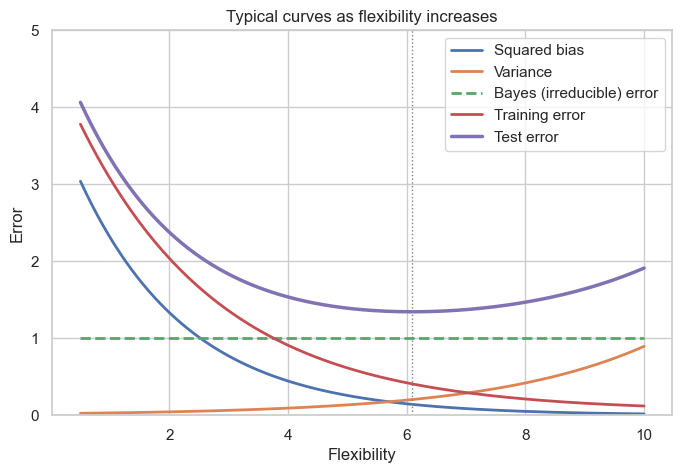

In [2]:
# Stylized curves: flexibility on the x-axis
x = np.linspace(0.5, 10, 300)
bias2 = 4.0 * np.exp(-0.55 * x)          # decreases fast, then flattens
variance = 0.02 * np.exp(0.38 * x)       # small at first, then increases fast
bayes = np.full_like(x, 1.0)             # constant: Var(epsilon)
test = bias2 + variance + bayes          # U-shape, always above Bayes error
train = 4.6 * np.exp(-0.42 * x) + 0.05   # decreases monotonically, goes below Bayes

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, bias2, label="Squared bias", lw=2)
ax.plot(x, variance, label="Variance", lw=2)
ax.plot(x, bayes, "--", label="Bayes (irreducible) error", lw=2)
ax.plot(x, train, label="Training error", lw=2)
ax.plot(x, test, label="Test error", lw=2.5)
ax.axvline(x[np.argmin(test)], color="gray", ls=":", lw=1)
ax.set_xlabel("Flexibility")
ax.set_ylabel("Error")
ax.set_ylim(0, 5)
ax.set_title("Typical curves as flexibility increases")
ax.legend()
plt.show()

### (b) Why each curve has its shape

- **Squared bias — decreases.** Bias is the error from approximating a complex real $f$ with a simple model. A more flexible model can follow more shapes, so it approximates $f$ better. The decrease is fast at first, then slow, because after some point the model already captures the main shape of $f$.
- **Variance — increases.** Variance is how much $\hat f$ changes when we fit it on a different training sample. A flexible model follows the individual points (including their noise), so a new sample gives a very different $\hat f$. It increases slowly at first, then fast.
- **Bayes (irreducible) error — horizontal line.** It is $\mathrm{Var}(\varepsilon)$, the noise in $Y$ that $X$ cannot explain. It does not depend on the model, so flexibility does not change it.
- **Training error — decreases monotonically.** Least squares (and most methods) minimize training error. More flexibility gives more freedom to fit the training points, so the error always goes down. It can go **below** the Bayes error, because the model starts to fit the noise. It can reach zero.
- **Test error — U-shape.** Expected test error $=$ variance $+$ bias$^2$ $+$ Var($\varepsilon$) (eq. 2.7). At low flexibility, bias decreases faster than variance increases, so test error goes down. At high flexibility, bias is almost flat but variance increases fast, so test error goes up (**overfitting**). It is **always above** the Bayes error line.

**Quiz check:** the vertical dotted line is the best flexibility. The gap between training and test error grows with flexibility.

## Q2. Very flexible versus less flexible methods

**Advantages of a very flexible method**
- Lower bias: it can fit a non-linear or complex $f$.
- Can give better predictions when $f$ is far from the simple form.

**Disadvantages of a very flexible method**
- Higher variance and risk of overfitting (it fits noise).
- Needs more observations to estimate many parameters.
- Harder to interpret, so it is less useful for inference.
- More computation.

**Prefer a more flexible method when:**
- The goal is **prediction**, not interpretation.
- $n$ is **large** compared to $p$ (enough data to keep variance low).
- The true $f$ is probably **non-linear**.
- The noise $\mathrm{Var}(\varepsilon)$ is **small**.

**Prefer a less flexible method when:**
- The goal is **inference** (which predictors matter, and how much).
- $n$ is **small** or $p$ is large compared to $n$.
- The noise is **large** (a flexible model would fit the noise).
- The true $f$ is close to linear (then the simple model has little bias and wins on variance).

## Q3. Boston data

### (a) Load the data

In [3]:
Boston = load_data("Boston")
Boston.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,0.006,18.0,2.31,0,0.538,6.575,65.2,4.090,1,296,15.3,4.98,24.0
1,0.027,0.0,7.07,0,0.469,6.421,78.9,4.967,2,242,17.8,9.14,21.6
2,0.027,0.0,7.07,0,0.469,7.185,61.1,4.967,2,242,17.8,4.03,34.7
3,0.032,0.0,2.18,0,0.458,6.998,45.8,6.062,3,222,18.7,2.94,33.4
4,0.069,0.0,2.18,0,0.458,7.147,54.2,6.062,3,222,18.7,5.33,36.2


### (b) Rows and columns

In [4]:
Boston.shape

(506, 13)

**506 rows, 13 columns.** Each row is one **census tract** in the Boston area. Each column is a characteristic of that tract (all numeric): `crim` per-capita crime rate, `zn` share of residential land zoned for large lots, `indus` share of non-retail business acres, `chas` Charles River dummy, `nox` nitrogen-oxide concentration, `rm` average rooms per dwelling, `age` share of units built before 1940, `dis` distance to employment centres, `rad` highway accessibility index, `tax` property-tax rate per \$10,000, `ptratio` pupil-teacher ratio, `lstat` % lower-status population, `medv` median home value (\$1000s).

### (c) Pairwise scatterplots

First, some pairs of predictors (not crime) with each other.

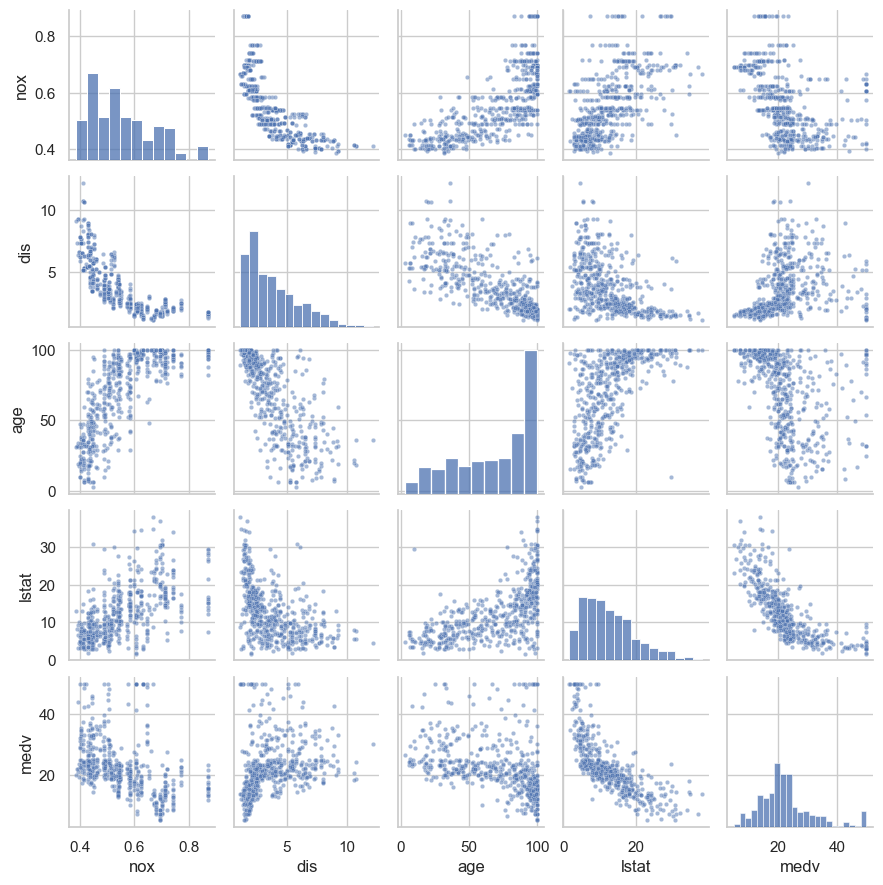

In [5]:
# Pairwise scatterplots among five predictors
sns.pairplot(Boston[["nox", "dis", "age", "lstat", "medv"]],
             plot_kws={"s": 10, "alpha": 0.5}, height=1.8)
plt.show()

Findings:
- **`nox` vs `dis`:** strong negative and curved. Tracts near employment centres have more air pollution.
- **`nox` vs `age`:** positive. Older areas (more pre-1940 housing) are more polluted; these are the old industrial core tracts.
- **`lstat` vs `medv`:** strong negative and curved. Home values fall fast as the share of lower-status population increases, then the decrease flattens.
- **`dis` vs `age`:** negative. Tracts far from the centre have newer housing.
- **`medv`** has a visible cap at 50 (16 tracts at exactly 50): the data are censored at the top.

Together these show one "urban core" pattern: old, dense, polluted, near the centre, lower values.

### (d) Predictors associated with crime

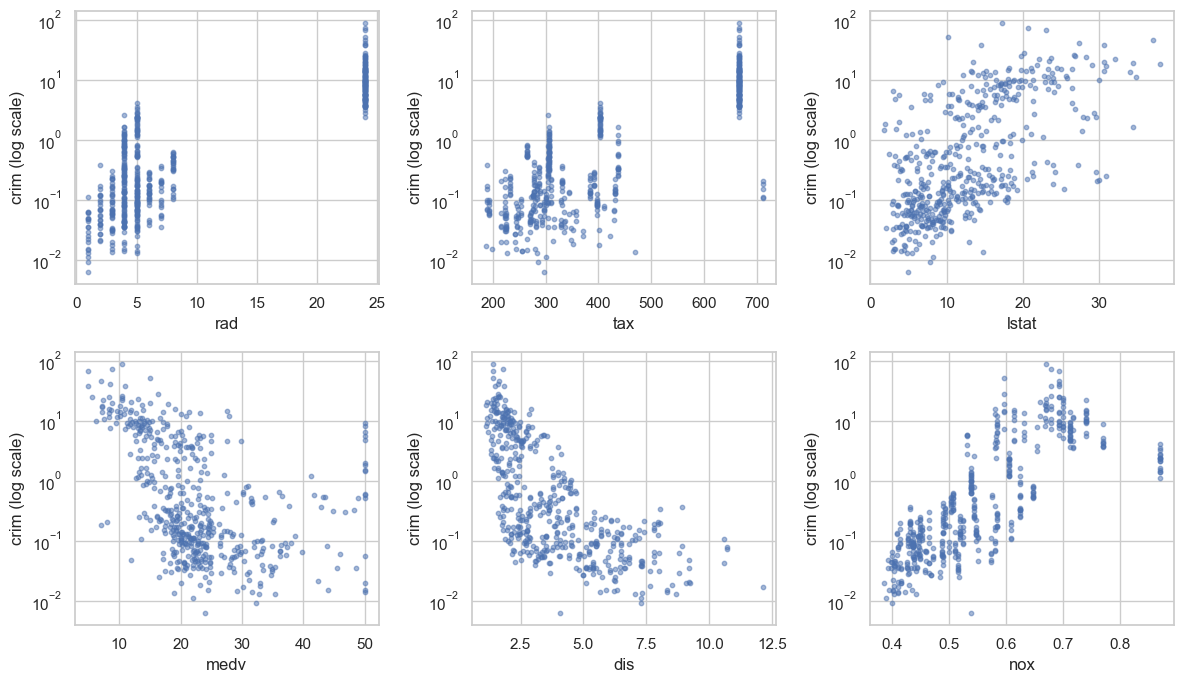

medv      -0.388
dis       -0.380
rm        -0.219
zn        -0.200
chas      -0.056
ptratio    0.290
age        0.353
indus      0.407
nox        0.421
lstat      0.456
tax        0.583
rad        0.626
Name: crim, dtype: float64

In [6]:
# crim is very right-skewed, so a log scale makes the patterns visible
xs = ["rad", "tax", "lstat", "medv", "dis", "nox"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, var in zip(axes.flat, xs):
    ax.scatter(Boston[var], Boston["crim"], s=10, alpha=0.5)
    ax.set_yscale("log")
    ax.set_xlabel(var)
    ax.set_ylabel("crim (log scale)")
plt.tight_layout()
plt.show()

# Correlation of each predictor with crim
Boston.corr()["crim"].drop("crim").sort_values()

In [7]:
# All high-crime tracts share one rad value and one tax value
print("Tracts with rad = 24:", (Boston["rad"] == 24).sum())
print("Tracts with tax = 666:", (Boston["tax"] == 666).sum())
print("Tracts with crim > 20:", (Boston["crim"] > 20).sum(),
      "| of which rad = 24:", ((Boston["crim"] > 20) & (Boston["rad"] == 24)).sum())
Boston.groupby(Boston["rad"] == 24)["crim"].agg(["count", "median", "mean"])

Tracts with rad = 24: 132
Tracts with tax = 666: 132
Tracts with crim > 20: 18 | of which rad = 24: 18


,count,median,mean
rad,,,
False,374,0.132,0.386
True,132,9.085,12.759


Yes, several predictors are associated with crime:

- **`rad` and `tax` (strongest, r ≈ 0.63 and 0.58).** The association is **not** a smooth line. It comes from one group: the 132 tracts with `rad = 24` and `tax = 666`. This group has median crime ≈ 9.1, versus ≈ 0.13 for all other tracts. **All 18 tracts with crime > 20 are in this group.** These are probably tracts in one jurisdiction (likely the city of Boston itself), so `rad` and `tax` are labels for "inner city" more than causes.
- **`lstat` (positive, r ≈ 0.46).** More lower-status population, more crime. Very high crime appears only above about 10–15%.
- **`medv` (negative, r ≈ −0.39).** Lower home values, more crime. High crime occurs almost only in tracts with `medv` < 20.
- **`dis` (negative, curved).** Crime is high only very near employment centres (`dis` < 3) and near zero far away.
- **`nox` (positive).** More polluted tracts have more crime — again the urban-core pattern.

These are associations only. The predictors are correlated with each other, so we cannot say which one "drives" crime (Q5 returns to this).

### (e) Particularly high crime rates, tax rates and pupil-teacher ratios

In [8]:
Boston[["crim", "tax", "ptratio"]].describe()

,crim,tax,ptratio
count,506.000,506.000,506.000
mean,3.614,408.237,18.456
std,8.602,168.537,2.165
min,0.006,187.000,12.600
25%,0.082,279.000,17.400
50%,0.257,330.000,19.050
75%,3.677,666.000,20.200
max,88.976,711.000,22.000


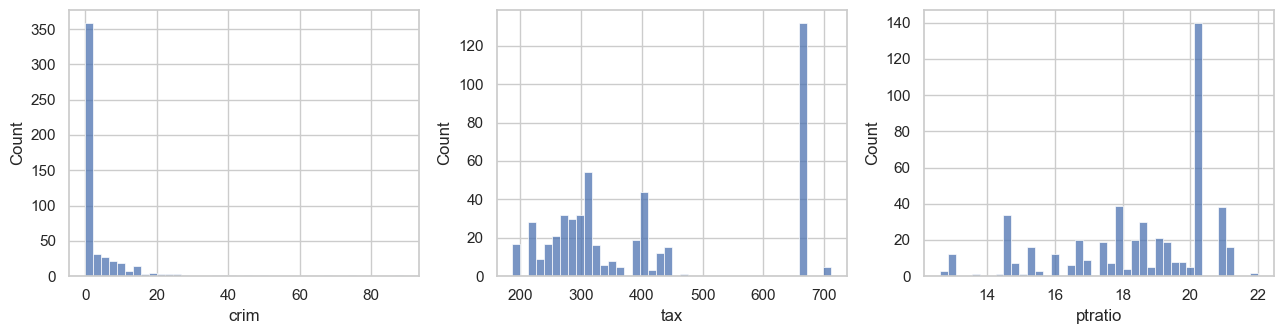

Tracts with ptratio = 20.2: 140


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, var in zip(axes, ["crim", "tax", "ptratio"]):
    sns.histplot(Boston[var], bins=40, ax=ax)
plt.tight_layout()
plt.show()

print("Tracts with ptratio = 20.2:", (Boston["ptratio"] == 20.2).sum())

Compare each variable with **its own** median and quartiles (not standard deviations across variables, because the units are different).

- **Crime: yes, some tracts are extreme.** Range 0.006 to 89.0. The median is only 0.26 and 75% of tracts are below 3.7, but the maximum is about **350 times the median**. A small group of tracts has very high crime.
- **Tax: yes, but as a separate group, not as outliers.** Range 187 to 711. The distribution has **two groups**: most tracts are between about 190 and 470, and **132 tracts have exactly 666** (also the 75th percentile). There is a gap between the groups. This looks like one jurisdiction with one tax rate.
- **Pupil-teacher ratio: no extreme values.** Range 12.6 to 22.0, a narrow band. The distribution is skewed to the left (a few tracts with low ratios). **140 tracts have exactly 20.2** — again, the same jurisdiction effect.

### (f) Tracts that bound the Charles River

In [10]:
Boston["chas"].sum()

np.int64(35)

**35 tracts** (about 7%) bound the Charles River.

### (g) Median pupil-teacher ratio

In [11]:
Boston["ptratio"].median()

np.float64(19.05)

The median pupil-teacher ratio is **19.05**.

### (h) Tract with the lowest median home value

In [12]:
lowest = Boston[Boston["medv"] == Boston["medv"].min()]

# Compare the two tracts with the range of each predictor
summary = Boston.describe().T[["min", "50%", "max"]]
comparison = summary.join(lowest.T.add_prefix("row_"))
comparison

,min,50%,max,row_398,row_405
crim,0.006,0.257,88.976,38.352,67.921
zn,0.000,0.000,100.000,0.000,0.000
indus,0.460,9.690,27.740,18.100,18.100
chas,0.000,0.000,1.000,0.000,0.000
nox,0.385,0.538,0.871,0.693,0.693
rm,3.561,6.208,8.780,5.453,5.683
age,2.900,77.500,100.000,100.000,100.000
dis,1.130,3.207,12.127,1.490,1.425
rad,1.000,5.000,24.000,24.000,24.000
tax,187.000,330.000,711.000,666.000,666.000


Two tracts tie for the lowest value, **`medv` = 5.0 (\$5,000)**: rows 398 and 405 (0-based index). Compared with the ranges:

- **Crime:** 38.4 and 67.9 — near the **top** of the range (median 0.26).
- **`age` = 100:** the **maximum** — all housing is pre-1940.
- **`rad` = 24, `tax` = 666:** the **maximum** values; both tracts are in the high-crime group from (d).
- **`dis`** ≈ 1.4–1.5: near the **minimum** — very close to employment centres.
- **`lstat`** 23–31%: far above the median of 11.4%.
- **`indus` = 18.1, `nox` = 0.693, `ptratio` = 20.2:** all above the median.
- **`rm`** ≈ 5.5–5.7: below the median — small dwellings.
- **`zn` = 0, `chas` = 0:** no large-lot zoning, not on the river.

**Comment:** these tracts are at the extreme of almost every "disadvantage" predictor at the same time. This shows how strongly the predictors move together, which matters for Q5.

### (i) Tracts with more than 7 and more than 8 rooms per dwelling

In [13]:
print("More than 7 rooms:", (Boston["rm"] > 7).sum())
print("More than 8 rooms:", (Boston["rm"] > 8).sum())

# Compare the > 8 rooms tracts with all tracts (medians)
pd.DataFrame({
    "rm > 8 (median)": Boston[Boston["rm"] > 8].median(),
    "all tracts (median)": Boston.median(),
})

More than 7 rooms: 64
More than 8 rooms: 13


,rm > 8 (median),all tracts (median)
crim,0.520,0.257
zn,0.000,0.000
indus,6.200,9.690
chas,0.000,0.000
nox,0.507,0.538
rm,8.297,6.208
age,78.300,77.500
dis,2.894,3.207
rad,7.000,5.000
tax,307.000,330.000


**64 tracts** average more than 7 rooms; **13 tracts** average more than 8 rooms.

The 13 tracts with more than 8 rooms are the opposite of the tracts in (h):
- **Home value:** median `medv` 48.3, versus 21.2 overall (several are at the cap of 50).
- **`lstat`:** about 4%, versus 11.4% overall.
- **Crime:** low (median 0.52; mean 0.72 versus 3.6 overall). None are in the `rad = 24` group.
- **Lower `ptratio`** (17.4 versus 19.05) and **lower tax** (307 versus 330).

These are affluent tracts: large homes, high values, low crime.

## Q4. Interaction terms

$\hat y = 50 + 20\,\text{GPA} + 0.07\,\text{IQ} + 35\,\text{Level} + 0.01\,(\text{GPA}\times\text{IQ}) - 10\,(\text{GPA}\times\text{Level})$

### (a)
Write the model for each group (same GPA and IQ):

- **College** (Level = 1): $\hat y = 85 + 10\,\text{GPA} + 0.07\,\text{IQ} + 0.01\,\text{GPA}\times\text{IQ}$
- **High school** (Level = 0): $\hat y = 50 + 20\,\text{GPA} + 0.07\,\text{IQ} + 0.01\,\text{GPA}\times\text{IQ}$

**College − High school $= 35 - 10\,\text{GPA}$.**

This is negative when GPA > 3.5. So **answer (iii) is correct:** for fixed IQ and GPA, high school graduates earn more on average, provided that the GPA is high enough (above 3.5). (i) and (ii) are wrong because the difference changes sign; (iv) has the direction reversed.

### (b)

In [14]:
# College graduate, IQ = 110, GPA = 4.0
gpa, iq, level = 4.0, 110, 1
salary = 50 + 20*gpa + 0.07*iq + 35*level + 0.01*gpa*iq - 10*gpa*level
salary  # thousands of dollars

137.1

$50 + 80 + 7.7 + 35 + 4.4 - 40 = 137.1$, so the predicted salary is **\$137,100**.

### (c)
**False.** The size of a coefficient depends on the **units** of the variable. GPA × IQ is a large number (4.0 × 110 = 440), so $0.01 \times 440 = 4.4$ — about \$4,400, not a small effect. More important: **evidence** for an interaction comes from the **standard error** (t-statistic, p-value), not from the size of $\hat\beta$. The question gives no standard error, so we cannot judge the evidence from the coefficient alone.

## Q5. Predict per-capita crime

### (a) One simple regression per predictor

In [15]:
predictors = [c for c in Boston.columns if c != "crim"]

def simple_fit(var):
    # Fit crim ~ var and return the main results
    fit = smf.ols(f"crim ~ {var}", data=Boston).fit()
    return {"coef": fit.params[var], "p_value": fit.pvalues[var], "R2": fit.rsquared}

simple = pd.DataFrame({v: simple_fit(v) for v in predictors}).T
simple["significant_5pct"] = simple["p_value"] < 0.05
simple.sort_values("R2", ascending=False)

,coef,p_value,R2,significant_5pct
rad,0.618,2.694e-56,0.391,True
tax,0.030,2.357e-47,0.340,True
lstat,0.549,2.654e-27,0.208,True
nox,31.249,3.752e-23,0.177,True
indus,0.510,1.450e-21,0.165,True
medv,-0.363,1.174e-19,0.151,True
dis,-1.551,8.520e-19,0.144,True
age,0.108,2.855e-16,0.124,True
ptratio,1.152,2.943e-11,0.084,True
rm,-2.684,6.347e-07,0.048,True


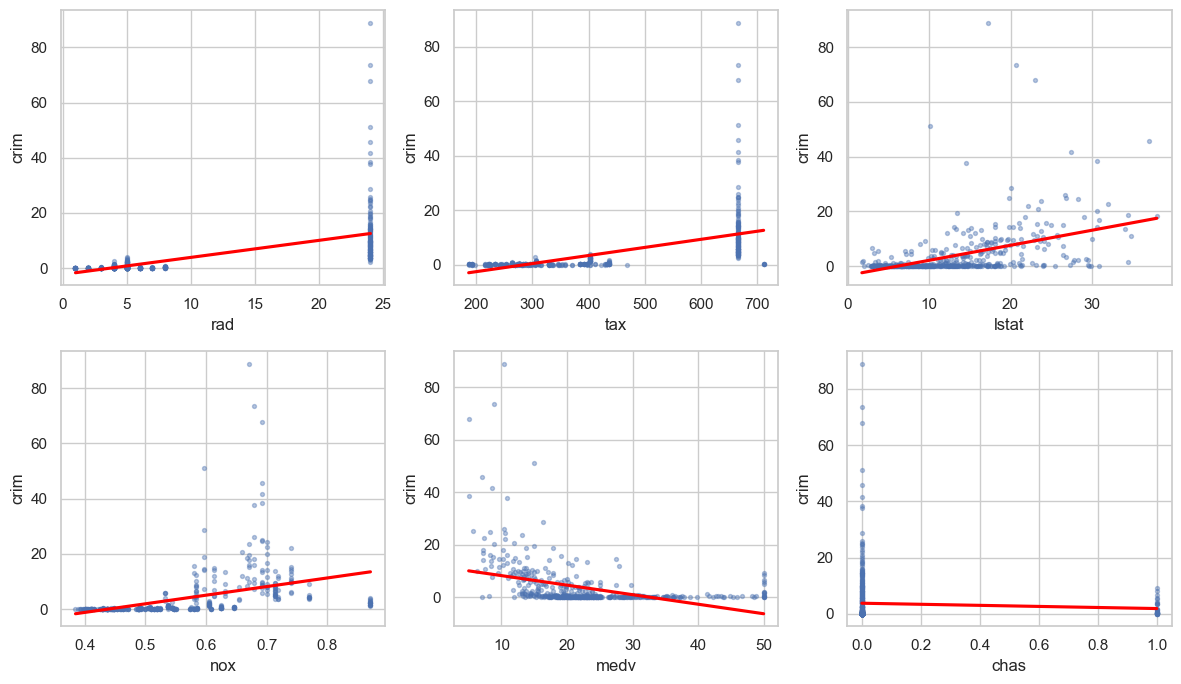

In [16]:
# Plots with the fitted line for six predictors
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, var in zip(axes.flat, ["rad", "tax", "lstat", "nox", "medv", "chas"]):
    sns.regplot(x=var, y="crim", data=Boston, ax=ax, ci=None,
                scatter_kws={"s": 8, "alpha": 0.4}, line_kws={"color": "red"})
plt.tight_layout()
plt.show()

- **Every predictor except `chas`** has a statistically significant association with crime (p < 0.05). `chas` has p ≈ 0.21: no evidence that being on the river is associated with crime.
- Positive: `indus`, `nox`, `age`, `rad`, `tax`, `ptratio`, `lstat`. Negative: `zn`, `rm`, `dis`, `medv`.
- `rad` (R² ≈ 0.39) and `tax` (R² ≈ 0.34) explain the most variation; `chas` (0.003), `zn` (0.04) and `rm` (0.05) the least.
- **Caution, visible in the plots:** for `rad` and `tax`, the straight line only connects two clusters (the `rad = 24 / tax = 666` group and the rest). The linear model is a poor description of these relations. Also, `crim` is very skewed and its spread grows with the predictors, so the OLS p-values are approximate.

### (b) Multiple regression with all predictors

In [17]:
formula = "crim ~ " + " + ".join(predictors)
multi = smf.ols(formula, data=Boston).fit()
print(f"R2 = {multi.rsquared:.3f}, adj. R2 = {multi.rsquared_adj:.3f}, F p-value = {multi.f_pvalue:.2g}")

multi_tab = pd.DataFrame({"coef": multi.params, "p_value": multi.pvalues}).drop("Intercept")
multi_tab["reject_H0_5pct"] = multi_tab["p_value"] < 0.05
multi_tab

R2 = 0.449, adj. R2 = 0.436, F p-value = 2e-56


,coef,p_value,reject_H0_5pct
zn,4.571e-02,1.534e-02,True
indus,-5.835e-02,4.857e-01,False
chas,-8.254e-01,4.858e-01,False
nox,-9.958e+00,6.037e-02,False
rm,6.289e-01,3.007e-01,False
age,-8.483e-04,9.623e-01,False
dis,-1.012e+00,3.726e-04,True
rad,6.125e-01,8.588e-12,True
tax,-3.776e-03,4.658e-01,False
ptratio,-3.041e-01,1.034e-01,False


- The full model explains about **45%** of the variation in crime (adj. R² ≈ 0.44). The F-test rejects that all coefficients are zero.
- We can reject $H_0: \beta_j = 0$ at the 5% level for **`zn`, `dis`, `rad`, and `medv`** only.
  - `rad` (+0.61): higher highway-access index, more crime, holding the rest constant.
  - `dis` (−1.01): farther from employment centres, less crime.
  - `medv` (−0.22): higher home values, less crime.
  - `zn` (+0.05): a small positive effect — the sign is **reversed** from the simple regression.
- `nox` (p ≈ 0.06) and `lstat` (p ≈ 0.07) are close to the threshold. All others are far from significant.

### (c) Simple versus multiple regression coefficients

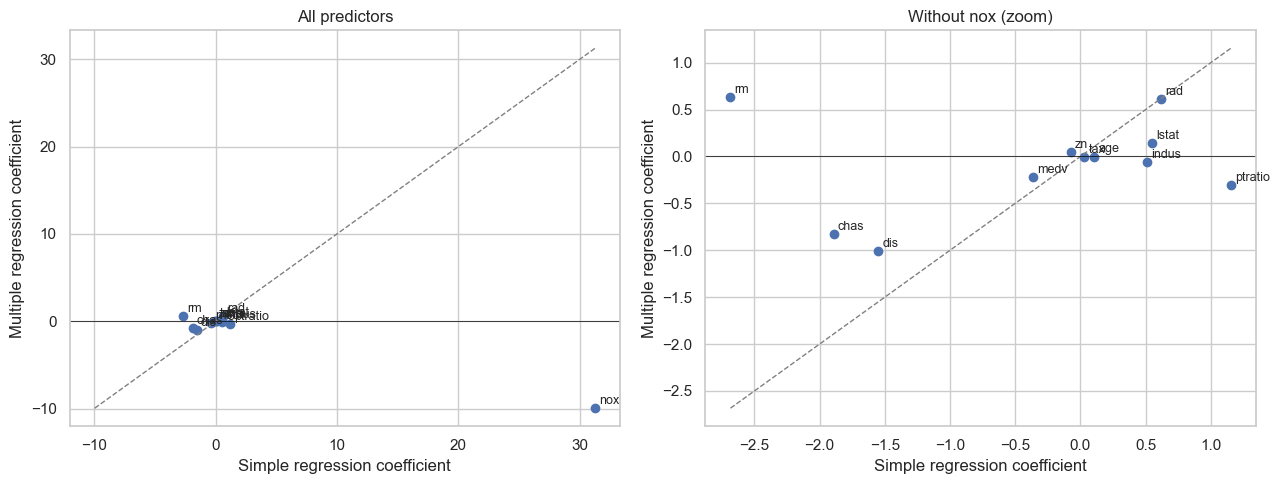

,rad,tax,nox,indus,dis,age,lstat,medv
rad,1.00,0.91,0.61,0.60,-0.49,0.46,0.49,-0.38
tax,0.91,1.00,0.67,0.72,-0.53,0.51,0.54,-0.47
nox,0.61,0.67,1.00,0.76,-0.77,0.73,0.59,-0.43
indus,0.60,0.72,0.76,1.00,-0.71,0.64,0.60,-0.48
dis,-0.49,-0.53,-0.77,-0.71,1.00,-0.75,-0.50,0.25
age,0.46,0.51,0.73,0.64,-0.75,1.00,0.60,-0.38
lstat,0.49,0.54,0.59,0.60,-0.50,0.60,1.00,-0.74
medv,-0.38,-0.47,-0.43,-0.48,0.25,-0.38,-0.74,1.00


In [18]:
coefs = pd.DataFrame({"simple": simple["coef"], "multiple": multi_tab["coef"]})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, data, title in [(axes[0], coefs, "All predictors"),
                        (axes[1], coefs.drop("nox"), "Without nox (zoom)")]:
    ax.scatter(data["simple"], data["multiple"])
    for name, row in data.iterrows():
        ax.annotate(name, (row["simple"], row["multiple"]), fontsize=9,
                    xytext=(3, 3), textcoords="offset points")
    lims = [min(data.min()), max(data.max())]
    ax.plot(lims, lims, ls="--", color="gray", lw=1)   # 45-degree line
    ax.axhline(0, color="black", lw=0.5)
    ax.set_xlabel("Simple regression coefficient")
    ax.set_ylabel("Multiple regression coefficient")
    ax.set_title(title)
plt.tight_layout()
plt.show()

# Correlations that explain the differences
Boston[["rad", "tax", "nox", "indus", "dis", "age", "lstat", "medv"]].corr().round(2)

The results are **very different**. In (a), all 11 non-dummy predictors are significant; in (b), only 4 are. Several coefficients become much smaller, and some change sign:

- **`nox`:** +31.2 alone, but −10.0 in the full model (it is far from the 45° line).
- **`rm`:** −2.7 alone, +0.6 in the full model. **`zn`** and **`ptratio`** also change sign.
- **`tax`:** strongly significant alone, not significant in the full model.

**Why.** A simple-regression coefficient measures the association while **ignoring** the other predictors. The multiple-regression coefficient measures it while **holding the others constant**. The predictors are highly correlated (e.g., `rad`–`tax` r = 0.91, `nox`–`dis` r = −0.77, `nox`–`indus` r = 0.76). So in a simple regression, `tax` receives credit for the effect it shares with `rad`. When both are in the model, `rad` keeps the effect and `tax` loses it. This is the same mechanism as the newspaper example in ISL Section 3.2. High correlation among predictors (collinearity) also inflates standard errors, which makes significance harder to find.

### (d) Non-linear association

In [19]:
def cubic_fit(var):
    # Fit crim ~ X + X^2 + X^3 and keep the p-values for the non-linear terms
    fit = smf.ols(f"crim ~ {var} + I({var}**2) + I({var}**3)", data=Boston).fit()
    return {"p_X2": fit.pvalues[f"I({var} ** 2)"],
            "p_X3": fit.pvalues[f"I({var} ** 3)"],
            "R2_linear": simple.loc[var, "R2"],
            "R2_cubic": fit.rsquared}

cubic = pd.DataFrame({v: cubic_fit(v) for v in predictors if v != "chas"}).T
cubic["nonlinear_5pct"] = (cubic["p_X2"] < 0.05) | (cubic["p_X3"] < 0.05)
cubic.sort_values("p_X3")

,p_X2,p_X3,R2_linear,R2_cubic,nonlinear_5pct
nox,6.811e-15,6.961e-16,0.177,0.297,True
medv,3.261e-18,1.047e-12,0.151,0.420,True
indus,3.420e-10,1.196e-12,0.165,0.260,True
dis,4.941e-12,1.089e-08,0.144,0.278,True
ptratio,4.120e-03,6.301e-03,0.084,0.114,True
age,4.738e-02,6.680e-03,0.124,0.174,True
lstat,6.459e-02,1.299e-01,0.208,0.218,False
zn,9.375e-02,2.295e-01,0.040,0.058,False
tax,1.375e-01,2.439e-01,0.340,0.369,False
rad,6.130e-01,4.823e-01,0.391,0.400,False


(`chas` is excluded: it is 0/1, so $X^2 = X^3 = X$.)

- **Evidence of non-linearity** (X² or X³ significant at 5%): **`indus`, `nox`, `dis`, `medv`, `ptratio`, `age`**. The strongest case is `medv`: R² increases from 0.15 to 0.42 with the cubic terms. `dis`, `nox` and `indus` also gain about 0.1 in R².
- **No evidence:** `zn`, `rm`, `rad`, `tax`, `lstat`.
- **Caution on `rad` and `tax`:** the cubic terms are not significant, but this does not mean the relation is linear. These variables have a few discrete values and one large cluster (24 / 666), so a polynomial is not the right tool. A dummy for the cluster describes them better.
- With 11 tests, one or two "significant" results can occur by chance at the 5% level; the strong results (`medv`, `dis`, `nox`, `indus`, p < 0.001) are robust to this.

---
## Quiz review: five things to know without notes

1. Expected test MSE $=$ Var($\hat f$) $+$ Bias² $+$ Var($\varepsilon$). Test error can never go below Var($\varepsilon$); training error can.
2. More flexibility: bias ↓, variance ↑, training error ↓ always, test error U-shaped.
3. With a dummy interaction, the group difference is a function of the other variable: here $35 - 10\,\text{GPA}$.
4. Coefficient **size** depends on units; **evidence** comes from SE / p-value.
5. Simple and multiple regression coefficients differ when predictors are correlated. A predictor can be significant alone and not significant (or change sign) when you control for others.